In [4]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from langchain.agents.structured_output import ToolStrategy
from typing import Literal, Dict, Any
from dotenv import load_dotenv
from pydantic import BaseModel, Field, model_validator
load_dotenv()

class ModelResponseFormat(BaseModel):
    """Agent Response format"""
    information: str
    claim: str
    source_claim: str


model = ChatGroq(
    model="openai/gpt-oss-20b"
)
model_with_structure = model.with_structured_output(ModelResponseFormat)
@tool
def web_search(query: str, max_results: int = 2, topics: Literal["general", "news", "finance" ] = "general", include_raw_content: bool = True) -> Dict[str, Any]:
    """web search tool that reterives the data from web"""
    res =  TavilySearch(topic=topics, max_results= 1, include_raw_content=include_raw_content).invoke(query)
    print("websearch result : ", res)
    return res

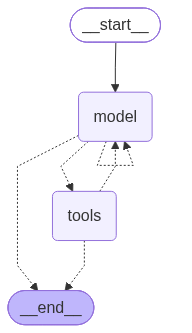

In [2]:
"""
Implement Quote Verification
tell the agent to return the claim along with source quote 
compare with reterived document 
if source quote in reterived document 
returns Evidence Found
else return evidence not found
"""

agent = create_agent(
    model=model,
    system_prompt="""
    you are a helpful assistant which fetches the current data using web search tool when asked, 
    only reterive maximum 3 websearch results and relay on it for evidence grounded answer
    and return the response claim along with source claim which you used for generating the respone in provided structure.
    """,
    tools=[web_search],
    response_format=ToolStrategy(ModelResponseFormat)
)
agent

In [3]:
agent_res = agent.invoke({
    "messages":[{
        "role": "user",
        "content": "According to current Market standards which Car is better in terms of performace and reliability either Volkswagen virtus or Thar rox 4x4"
    }],
})
agent_res

websearch result :  {'query': 'Volkswagen Virtus performance reliability vs Thar Rox 4x4 comparison', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.zigwheels.com/compare-cars/mahindra-thar-roxx-vs-volkswagen-virtus', 'title': 'Thar ROXX vs Virtus: Price, Specs & Verdict', 'content': "Volkswagen Virtus price starts at Rs. 10.71 Lakh, which is Rs. 1.81 Lakh cheaper than the base variant of Mahindra Thar ROXX, priced at Rs. 12.52 Lakh. In terms of mileage, the Thar ROXX offers a claimed 12.4 kmpl, while the Virtus delivers 20.19 kmpl. On the performance front, the Thar ROXX uses a 1997cc engine producing 160bhp@5000rpm and the Virtus a 999cc engine producing 113.98bhp@5000-5500rpm. If you're deciding between the Thar ROXX and Virtus, the Virtus is the better pick for [...] 67% users have chosen Volkswagen Virtus over Mahindra Thar ROXX in a survey being conducted on zigwheels.com. Apart from this survey a total of 217 users have also rated Vol

APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `openai/gpt-oss-20b` in organization `org_01m0fnmyjte36bwmy5y9ytzy57` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Requested 20551, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}